In [43]:
import healpy as hp
import matplotlib.pyplot as plt
import numpy as np

# uses the CAMB cosmology which produced the cls
import camb
from cosmology.compat.camb import Cosmology

# almost all GLASS functionality is available from the `glass` namespace
import glass
import glass.ext.camb

# creating a numpy random number generator for sampling
rng = np.random.default_rng(seed=42)

# cosmology for the simulation
h = 0.7
Oc = 0.25
Ob = 0.05

# basic parameters of the simulation
nside = 1024
lmax = 1000

# set up CAMB parameters for matter angular power spectrum
pars = camb.set_params(
    H0=100 * h,
    omch2=Oc * h**2,
    ombh2=Ob * h**2,
    NonLinear=camb.model.NonLinear_both,
)
results = camb.get_background(pars)

# get the cosmology from CAMB
cosmo = Cosmology(results)

In [2]:

# shells of 200 Mpc in comoving distance spacing
zb = glass.distance_grid(cosmo, 0.0, 1.0, dx=200.0)

# triangular radial windows, equivalent to linear interpolation of n(z)
shells = glass.linear_windows(zb)


In [61]:
zb

array([0.        , 0.04720758, 0.09549701, 0.14497038, 0.19573705,
       0.24791427, 0.30162785, 0.35701293, 0.41421483, 0.47338998,
       0.53470703, 0.59834803, 0.66450979, 0.7334054 , 0.80526596,
       0.88034252, 0.95890826, 1.04126102])

In [52]:
cls_test = glass.ext.camb.matter_cls(pars, lmax, [shells[0]])

In [3]:
# compute angular matter power spectra with CAMB
cls = glass.ext.camb.matter_cls(pars, lmax, shells)


In [5]:
%%time
# apply discretisation to the full set of spectra:
# - HEALPix pixel window function (`nside=nside`)
# - maximum angular mode number (`lmax=lmax`)
# - number of correlated shells (`ncorr=3`)
cls = glass.discretized_cls(cls, nside=nside, lmax=lmax, ncorr=3)


CPU times: user 14.8 ms, sys: 7.99 ms, total: 22.8 ms
Wall time: 237 ms


In [8]:

# set up lognormal fields for simulation
fields = glass.lognormal_fields(shells)


In [9]:
# compute Gaussian spectra for lognormal fields from discretised spectra
gls = glass.solve_gaussian_spectra(fields, cls)


In [55]:

# this generator will yield the matter fields in each shell
matter = glass.generate(fields, gls, nside, ncorr=3, rng=rng)


In [33]:
zb

array([0.        , 0.04720758, 0.09549701, 0.14497038, 0.19573705,
       0.24791427, 0.30162785, 0.35701293, 0.41421483, 0.47338998,
       0.53470703, 0.59834803, 0.66450979, 0.7334054 , 0.80526596,
       0.88034252, 0.95890826, 1.04126102])

In [56]:
for i, delta_i in enumerate(matter):
    if i == 0:
        test_delta_i = delta_i

<Figure size 1200x1000 with 0 Axes>

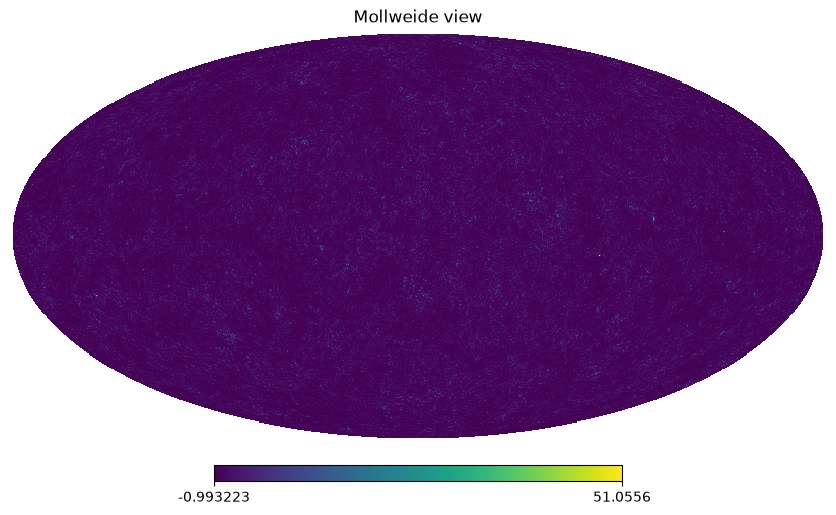

In [57]:
fig = plt.figure(figsize=(12,10))
hp.mollview(test_delta_i)

In [58]:
cl_mm_test = hp.anafast(test_delta_i, lmax=500, use_pixel_weights=True)

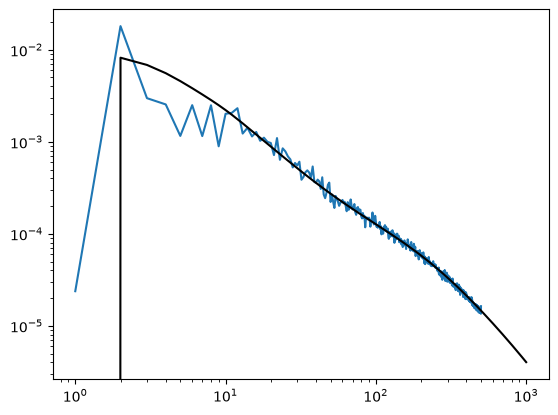

In [60]:
plt.loglog(np.arange(1, len(cl_mm_test)+1), cl_mm_test)
plt.loglog(np.arange(1, 1002), cls_test[0], c='k')

In [ ]:
cls

In [12]:
# make a 2d grid in redshift
n = 2000
zend = 1.05 * zb[-1]
x, y = np.mgrid[-zend : zend : 1j * n, -zend : zend : 1j * n]
z = np.hypot(x, y)
grid = np.full(z.shape, np.nan)

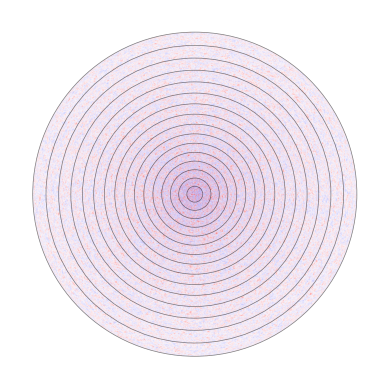

In [13]:

# set up the plot
ax = plt.subplot(111)
ax.axis("off")

# simulate and project an annulus of each matter shell onto the grid
for i, delta_i in enumerate(matter):
    zmin, zmax = zb[i], zb[i + 1]
    g = (zmin <= z) & (z < zmax)
    zg = np.sqrt(1 - (z[g] / zmax) ** 2)
    theta, phi = hp.vec2ang(np.transpose([x[g] / zmax, y[g] / zmax, zg]))
    grid[g] = hp.get_interp_val(delta_i, theta, phi)
    ax.add_patch(
        plt.Circle((0, 0), zmax / zend, fc="none", ec="k", lw=0.5, alpha=0.5, zorder=1),
    )

# show the grid of shells
ax.imshow(grid, extent=[-1, 1, -1, 1], zorder=0, cmap="bwr", vmin=-2, vmax=2)

# show the resulting plot
plt.show()